# 超参数调优前后：AAPL 与 TSLA 五模型对比

本页只读取指定的已完成实验，不训练模型、不加载模型权重，也不重新构造数据集。

- 默认比较 `aapl_compare_all_01 → aapl_compare_all_02` 与 `tsla_compare_all_01 → tsla_compare_all_02`。
- **唯一需要调整的入口是下面的 `RUN_PAIRS`**，每一项按“调优前、调优后”填写目录名；股票名称从各目录的 `config.json` 获取。
- 选择 **EE6008** 内核，执行 **Restart Kernel → Run All**。更换目录后必须重新运行全部单元格，旧输出不会自动刷新。
- 读取实验配置快照，不读取 `configs/` 当前配置，不扫描最新目录。所有指标使用完整验证集，不使用最终测试集或保留期。

阅读顺序：可比性检查 → 参数改动 → 指标明细 → 对比图 → 基线与排序 → 自动小结。

In [1]:
import json
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'main.py').is_file() and (p / 'src/evaluate.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('请从 stock_prediction 或 notebooks 目录打开此 Notebook')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import src.evaluate as evaluation
if Path(evaluation.__file__).resolve() != (ROOT / 'src/evaluate.py').resolve():
    raise RuntimeError('评价模块来自另一个项目目录，请重启内核')

# 每一对必须为（调优前目录名，调优后目录名），只写 artifacts 下的目录名。
# 不根据目录名判断股票；未来加入其他股票时可增加一对目录。
RUN_PAIRS = [
    ('aapl_compare_all_01', 'aapl_compare_all_02'),
    ('tsla_compare_all_01', 'tsla_compare_all_02'),
]
MODELS = ['xgboost', 'lightgbm', 'patchtst', 'lstm', 'gru']
BASELINES = ['zero_return', 'historical_mean', 'last_return']
LABELS = dict(zip(MODELS + BASELINES,
                 ['XGBoost', 'LightGBM', 'PatchTST', 'LSTM', 'GRU',
                  'Zero return', 'Historical mean', 'Last return']))
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
print('Python:', sys.executable)
print('Project:', ROOT)

Python: F:\Enviornment\miniforge3\envs\EE6008\python.exe
Project: F:\Singapore_study\EE6008\stock_prediction


## 1. 先确认比较的是同一任务

必须一致：股票、原始数据指纹、公共数据配置（包括种子）、特征顺序、预处理参数、验证日期与真实收益、简单基线预测。
旧配置未写 `nasdaq_features` 时按 `all` 处理。

这里会根据 `predictions.csv` **重新计算指标并与 `metrics.json` 核对**。这是结果核验，不是训练。
不依赖当前原始 CSV 或旧版 `Dataset` 对象，避免历史结果因数据加载模块变化而无法展示。

代码或环境指纹不同会单独列出。即使其他检查通过，也不能仅凭结果差异断定“所有改善都是超参数造成的”。本页不检查完整训练输入矩阵是否逐项相同，因为实验文件中没有保存它。

In [2]:
def read_json(path):
    return json.loads(path.read_text(encoding='utf-8-sig'))


def load_run(name):
    if not isinstance(name, str) or re.fullmatch(r'[A-Za-z0-9_-]+', name) is None:
        raise ValueError('只填写 artifacts 下的实验目录名，不填写完整路径')
    folder = ROOT / 'artifacts' / name
    required = ['config.json', 'manifest.json', 'preprocessing.json',
                'metrics.json', 'predictions.csv']
    missing = [file for file in required if not (folder / file).is_file()]
    if missing:
        raise FileNotFoundError(f'{name} 缺少文件：{missing}')
    run = {key: read_json(folder / f'{key}.json')
           for key in ['config', 'manifest', 'preprocessing', 'metrics']}
    run['name'] = name
    c, m = run['config'], run['manifest']
    if not isinstance(c.get('ticker'), str) or not c['ticker'].strip():
        raise ValueError(f'{name}: config.json 缺少 ticker')
    if (m.get('status') != 'complete' or m.get('evaluation_split') != 'validation'
            or m.get('test_evaluated', False) or m.get('holdout_evaluated', False)):
        raise ValueError(f'{name}: 仅接受已完成且未评价测试集/保留期的验证实验')
    if not m.get('data_sha256') or m.get('seed') != c.get('seed'):
        raise ValueError(f'{name}: 数据指纹缺失或 seed 记录不一致')
    if run['preprocessing'].get('window') != c.get('window'):
        raise ValueError(f'{name}: 窗口记录不一致')
    if any(model not in c for model in MODELS):
        raise ValueError(f'{name}: 缺少五模型配置')
    pred = pd.read_csv(folder / 'predictions.csv', float_precision='round_trip')
    dates = ['window_start', 'signal_date', 'target_date']
    columns = dates + ['actual_return', 'actual_direction'] + BASELINES + MODELS
    if not set(columns).issubset(pred.columns):
        raise ValueError(f'{name}: 缺少日期、标签、基线或五模型预测列')
    for column in dates:
        pred[column] = pd.to_datetime(pred[column], errors='raise')
    if (len(pred) < 2 or pred[dates].isna().any().any()
            or pred.target_date.duplicated().any()
            or not pred.target_date.is_monotonic_increasing):
        raise ValueError(f'{name}: 验证日期为空、重复或未按时间排序')
    if not ((pred.window_start <= pred.signal_date) & (pred.signal_date < pred.target_date)).all():
        raise ValueError(f'{name}: 历史窗口、信号日与目标日顺序错误')
    if not ((pred.target_date > pd.Timestamp(c['train_end']))
            & (pred.target_date <= pd.Timestamp(c['validation_end']))).all():
        raise ValueError(f'{name}: 预测日期超出配置中的验证期')
    np.testing.assert_array_equal(pred.actual_direction, (pred.actual_return > 0).astype(int))
    # 所有指标使用完整验证集；不读取模型权重，不调用 fit_predict。
    metrics = {}
    for model in BASELINES + MODELS:
        if model not in run['metrics']:
            raise ValueError(f'{name}: metrics.json 缺少 {model}')
        metrics[model] = evaluation.evaluate(pred.actual_return.to_numpy(), pred[model].to_numpy())
        for key, value in metrics[model].items():
            saved = run['metrics'][model][key]
            if value is None or saved is None:
                if value != saved:
                    raise ValueError(f'{name}: {model}/{key} 指标不一致')
            else:
                np.testing.assert_allclose(value, saved, rtol=1e-8, atol=1e-12,
                    err_msg=f'{name}: {model}/{key} 与逐日预测不一致')
    run.update(predictions=pred, metrics=metrics)
    return run


def compare_protocol(before, after):
    # 模型段可不同；公共设置必须一致。不要把未指定的旧特征模式当作 6 特征。
    configs = []
    for run in (before, after):
        common = {k:v for k,v in run['config'].items() if k not in MODELS}
        common.setdefault('nasdaq_features', 'all')
        configs.append(common)
    if configs[0] != configs[1]:
        changed = [k for k in sorted(configs[0].keys() | configs[1].keys())
                   if configs[0].get(k) != configs[1].get(k)]
        raise ValueError(f'公共配置不同：{changed}，不能作为本页的同条件调参比较')
    if before['manifest']['data_sha256'] != after['manifest']['data_sha256']:
        raise ValueError('前后实验的原始数据指纹不同')
    pre, post = before['preprocessing'], after['preprocessing']
    if pre['features'] != post['features'] or pre['window'] != post['window']:
        raise ValueError('特征顺序或窗口不同')
    for key in ['feature_mean', 'feature_scale', 'target_mean', 'target_scale']:
        np.testing.assert_allclose(pre[key], post[key], rtol=1e-10, atol=1e-12,
                                   err_msg=f'预处理参数不同：{key}')
    a, b = before['predictions'], after['predictions']
    for key in ['window_start', 'signal_date', 'target_date', 'actual_direction']:
        np.testing.assert_array_equal(a[key], b[key], err_msg=f'前后 {key} 不一致')
    for key in ['actual_return', *BASELINES]:
        np.testing.assert_allclose(a[key], b[key], rtol=0, atol=1e-12,
                                   err_msg=f'前后 {key} 不一致')


def source_map(manifest):
    return {k.replace(chr(92), '/'):v for k,v in manifest.get('source_sha256', {}).items()}


pairs, audit_rows, provenance_rows = [], [], []
seen_stocks = set()
if not RUN_PAIRS:
    raise ValueError('请至少填写一对实验目录')
for before_name, after_name in RUN_PAIRS:
    if before_name == after_name:
        raise ValueError('前后实验不能是同一个目录')
    before, after = load_run(before_name), load_run(after_name)
    compare_protocol(before, after)
    ticker = before['config']['ticker']
    if ticker in seen_stocks:
        raise ValueError(f'{ticker} 重复：本页每只股票填写一对实验')
    seen_stocks.add(ticker)
    pairs.append((ticker, before, after))
    dates = before['predictions'].target_date
    audit_rows.append({'stock':ticker, 'before':before_name, 'after':after_name,
                       'n':len(dates), 'first_target':str(dates.min().date()),
                       'last_target':str(dates.max().date()),
                       'features':len(before['preprocessing']['features']),
                       'window':before['config']['window'], 'seed':before['config']['seed']})
    old_sources, new_sources = source_map(before['manifest']), source_map(after['manifest'])
    if not old_sources or not new_sources:
        provenance_rows.append({'stock':ticker, 'item':'source_sha256', 'note':'缺少代码指纹，无法核对'})
    for key in sorted(old_sources.keys() | new_sources.keys()):
        if old_sources.get(key) != new_sources.get(key):
            provenance_rows.append({'stock':ticker, 'item':key, 'note':'代码指纹不同'})
    for key in ['packages', 'python', 'gpu', 'cuda_build']:
        old, new = before['manifest'].get(key), after['manifest'].get(key)
        if old is None or new is None or old != new:
            provenance_rows.append({'stock':ticker, 'item':key,
                                   'note':f'环境不同或记录缺失：{old} → {new}'})

display(pd.DataFrame(audit_rows))
print('通过：相同数据指纹、公共配置、预处理、日期/标签/基线；保存指标与逐日预测一致。')
if provenance_rows:
    display(Markdown('**归因限制：下列代码或环境记录不同/缺失。可以比较保存的结果，但不能保证差异只来自超参数。**'))
    display(pd.DataFrame(provenance_rows))
else:
    print('前后代码与所记录的环境指纹一致。')

通过：相同数据指纹、公共配置、预处理、日期/标签/基线；保存指标与逐日预测一致。


,stock,before,after,n,first_target,last_target,features,window,seed
0,AAPL,aapl_compare_all_01,aapl_compare_all_02,501,2022-01-03,2023-12-29,8,60,42
1,TSLA,tsla_compare_all_01,tsla_compare_all_02,501,2022-01-03,2023-12-29,8,60,42


**归因限制：下列代码或环境记录不同/缺失。可以比较保存的结果，但不能保证差异只来自超参数。**

,stock,item,note
0,AAPL,scripts/run_experiment.py,代码指纹不同
1,AAPL,src/data.py,代码指纹不同
2,AAPL,src/models/lightgbm.py,代码指纹不同
3,TSLA,scripts/run_experiment.py,代码指纹不同
4,TSLA,src/data.py,代码指纹不同
5,TSLA,src/models/lightgbm.py,代码指纹不同


## 2. 每个模型实际改了什么参数？

只列出前后 `config.json` 不同的模型配置项。`未显式指定` 表示旧 JSON 没有这个字段，其实际默认值由当时实现决定，不自动猜成 0。
参数变动表记录的是配置差异，不证明每一个字段都被模型实际使用。

In [3]:
parameter_rows = []
for ticker, before, after in pairs:
    for model in MODELS:
        old, new = before['config'][model], after['config'][model]
        changes = [key for key in sorted(old.keys() | new.keys())
                   if key not in old or key not in new or old[key] != new[key]]
        for key in changes:
            parameter_rows.append({'stock':ticker, 'model':LABELS[model], 'parameter':key,
                'before':json.dumps(old[key], ensure_ascii=False) if key in old else '未显式指定',
                'after':json.dumps(new[key], ensure_ascii=False) if key in new else '未显式指定'})
        if not changes:
            parameter_rows.append({'stock':ticker, 'model':LABELS[model], 'parameter':'无配置变化',
                                   'before':'—', 'after':'—'})
parameter_changes = pd.DataFrame(parameter_rows)
for ticker, _, _ in pairs:
    display(Markdown(f'### {ticker}'))
    display(parameter_changes[parameter_changes.stock == ticker].drop(columns='stock').reset_index(drop=True))

### AAPL

,model,parameter,before,after
0,XGBoost,early_stopping_rounds,30,80
1,XGBoost,n_estimators,400,800
2,XGBoost,reg_alpha,未显式指定,0.15
3,LightGBM,colsample_bytree,0.8,0.85
4,LightGBM,early_stopping_rounds,30,80
5,LightGBM,learning_rate,0.03,0.0475
6,LightGBM,max_bin,未显式指定,127
7,LightGBM,max_depth,4,6
8,LightGBM,min_child_samples,50,28
9,LightGBM,min_split_gain,未显式指定,1.0


### TSLA

,model,parameter,before,after
0,XGBoost,early_stopping_rounds,30,80
1,XGBoost,n_estimators,400,800
2,XGBoost,reg_alpha,未显式指定,0.15
3,LightGBM,colsample_bytree,0.8,0.85
4,LightGBM,early_stopping_rounds,30,80
5,LightGBM,learning_rate,0.03,0.0475
6,LightGBM,max_bin,未显式指定,127
7,LightGBM,max_depth,4,6
8,LightGBM,min_child_samples,50,28
9,LightGBM,min_split_gain,未显式指定,1.0


## 3. 完整指标与变化幅度

- **MAE、RMSE 越低越好**，这里使用小数收益单位，`0.01` 对应 1 个百分点的收益误差。
- **R²、R² vs zero 越高越好**；后者大于 0 才表示平方误差低于零收益预测。
- 方向准确率、上涨 F1 越高通常越好，但需要结合预测上涨比例理解；总是预测上涨也可能得到较高的上涨 F1。
- `RMSE improvement (%) = 100 × (before − after) / before`，**正数表示误差下降**。
- `Direction change (pp) = 100 × (after − before)`，单位为百分点。F1 change 是 F1 的原始差值。
- 预测上涨比例没有“越高越好”的方向。平盘按“不涨”处理。

In [4]:
metric_keys = ['mae', 'rmse', 'r2', 'r2_vs_zero', 'direction_accuracy',
               'up_precision', 'up_recall', 'up_f1', 'predicted_up_rate']
records = []
for ticker, before, after in pairs:
    for model in MODELS:
        old, new = before['metrics'][model], after['metrics'][model]
        row = {'stock':ticker, 'model':model, 'n':old['n']}
        for metric in metric_keys:
            row[metric + '_before'], row[metric + '_after'] = old[metric], new[metric]
        row['rmse_improvement_pct'] = 100*(1-new['rmse']/old['rmse']) if old['rmse'] else np.nan
        row['mae_improvement_pct'] = 100*(1-new['mae']/old['mae']) if old['mae'] else np.nan
        row['direction_change_pp'] = 100*(new['direction_accuracy']-old['direction_accuracy'])
        row['f1_change'] = new['up_f1']-old['up_f1']
        row['beats_zero_after'] = new['rmse'] < after['metrics']['zero_return']['rmse']
        records.append(row)
comparison = pd.DataFrame(records)
for ticker, before, after in pairs:
    display(Markdown(f'### {ticker}：回归指标'))
    data = comparison[comparison.stock == ticker].set_index('model').loc[MODELS].rename(index=LABELS)
    columns = ['mae_before','mae_after','rmse_before','rmse_after',
               'r2_before','r2_after','r2_vs_zero_before','r2_vs_zero_after']
    display(data[columns].style.format('{:.6f}'))
    display(Markdown(f'### {ticker}：方向指标（真实上涨比例 {before["metrics"]["zero_return"]["actual_up_rate"]:.2%}）'))
    columns = [f'{key}_{phase}' for key in ['direction_accuracy','up_f1','predicted_up_rate']
               for phase in ['before','after']]
    formats = {key:('{:.4f}' if key.startswith('up_f1') else '{:.2%}') for key in columns}
    display(data[columns].style.format(formats))
    display(Markdown('**变化摘要：前三项正数表示改善，F1 change 正数也表示提高。**'))
    display(data[['rmse_improvement_pct','mae_improvement_pct','direction_change_pp',
                  'f1_change','beats_zero_after']].style.format({
        'rmse_improvement_pct':'{:+.4f}', 'mae_improvement_pct':'{:+.4f}',
        'direction_change_pp':'{:+.3f}', 'f1_change':'{:+.4f}'}))

### AAPL：回归指标

,mae_before,mae_after,rmse_before,rmse_after,r2_before,r2_after,r2_vs_zero_before,r2_vs_zero_after
model,,,,,,,,
XGBoost,0.013601,0.013574,0.018211,0.018198,0.010830,0.012318,0.011148,0.012637
LightGBM,0.013578,0.013608,0.018263,0.018042,0.005235,0.029092,0.005556,0.029405
PatchTST,0.014000,0.013996,0.018717,0.018712,-0.044819,-0.044259,-0.044482,-0.043923
LSTM,0.013600,0.013700,0.018315,0.018295,-0.000417,0.001717,-0.000094,0.002039
GRU,0.013606,0.013615,0.018315,0.018323,-0.000507,-0.001289,-0.000184,-0.000966


### AAPL：方向指标（真实上涨比例 51.30%）

,direction_accuracy_before,direction_accuracy_after,up_f1_before,up_f1_after,predicted_up_rate_before,predicted_up_rate_after
model,,,,,,
XGBoost,50.30%,50.70%,0.6498,0.6555,90.62%,91.82%
LightGBM,51.10%,51.50%,0.6639,0.6389,94.21%,83.03%
PatchTST,54.49%,54.49%,0.6250,0.6250,70.06%,70.06%
LSTM,51.30%,49.30%,0.6781,0.5621,100.00%,64.47%
GRU,51.50%,51.10%,0.6764,0.6349,98.60%,82.63%


**变化摘要：前三项正数表示改善，F1 change 正数也表示提高。**

...

,mae_before,mae_after,rmse_before,rmse_after,r2_before,r2_after,r2_vs_zero_before,r2_vs_zero_after
model,,,,,,,,
XGBoost,0.028754,0.028694,0.038220,0.038198,0.004735,0.005848,0.004736,0.005849
LightGBM,0.028713,0.028319,0.038306,0.037813,0.000207,0.025784,0.000208,0.025785
PatchTST,0.029406,0.029403,0.038877,0.038874,-0.029798,-0.029640,-0.029797,-0.029639
LSTM,0.028775,0.028819,0.038396,0.038232,-0.004499,0.004111,-0.004498,0.004112
GRU,0.028726,0.028749,0.038407,0.038433,-0.005064,-0.006417,-0.005063,-0.006416


### TSLA：方向指标（真实上涨比例 51.70%）

,direction_accuracy_before,direction_accuracy_after,up_f1_before,up_f1_after,predicted_up_rate_before,predicted_up_rate_after
model,,,,,,
XGBoost,50.90%,52.30%,0.6455,0.6438,86.83%,82.24%
LightGBM,53.69%,56.09%,0.6796,0.6405,92.81%,70.46%
PatchTST,53.09%,52.89%,0.4902,0.4892,40.32%,40.52%
LSTM,51.70%,52.30%,0.6816,0.5615,100.00%,57.09%
GRU,52.30%,52.69%,0.6818,0.6550,98.20%,85.43%


**变化摘要：前三项正数表示改善，F1 change 正数也表示提高。**

,rmse_improvement_pct,mae_improvement_pct,direction_change_pp,f1_change,beats_zero_after
model,,,,,
XGBoost,+0.0560,+0.2093,+1.397,-0.0017,True
LightGBM,+1.2874,+1.3723,+2.395,-0.0390,True
PatchTST,+0.0077,+0.0110,-0.200,-0.0011,False
LSTM,+0.4295,-0.1544,+0.599,-0.1201,True
GRU,-0.0673,-0.0783,+0.399,-0.0267,False


## 4. 前后指标对比图

蓝色为调优前，橙色为调优后。误差图乘以 100，展示收益百分点；方向图为百分比。每只股票单独绘图，避免把波动水平不同的股票直接混在一起比较原始 RMSE。
零收益基线用在回归误差图，训练期平均收益基线用在方向图；后者在当前实验中相当于一直预测上涨。

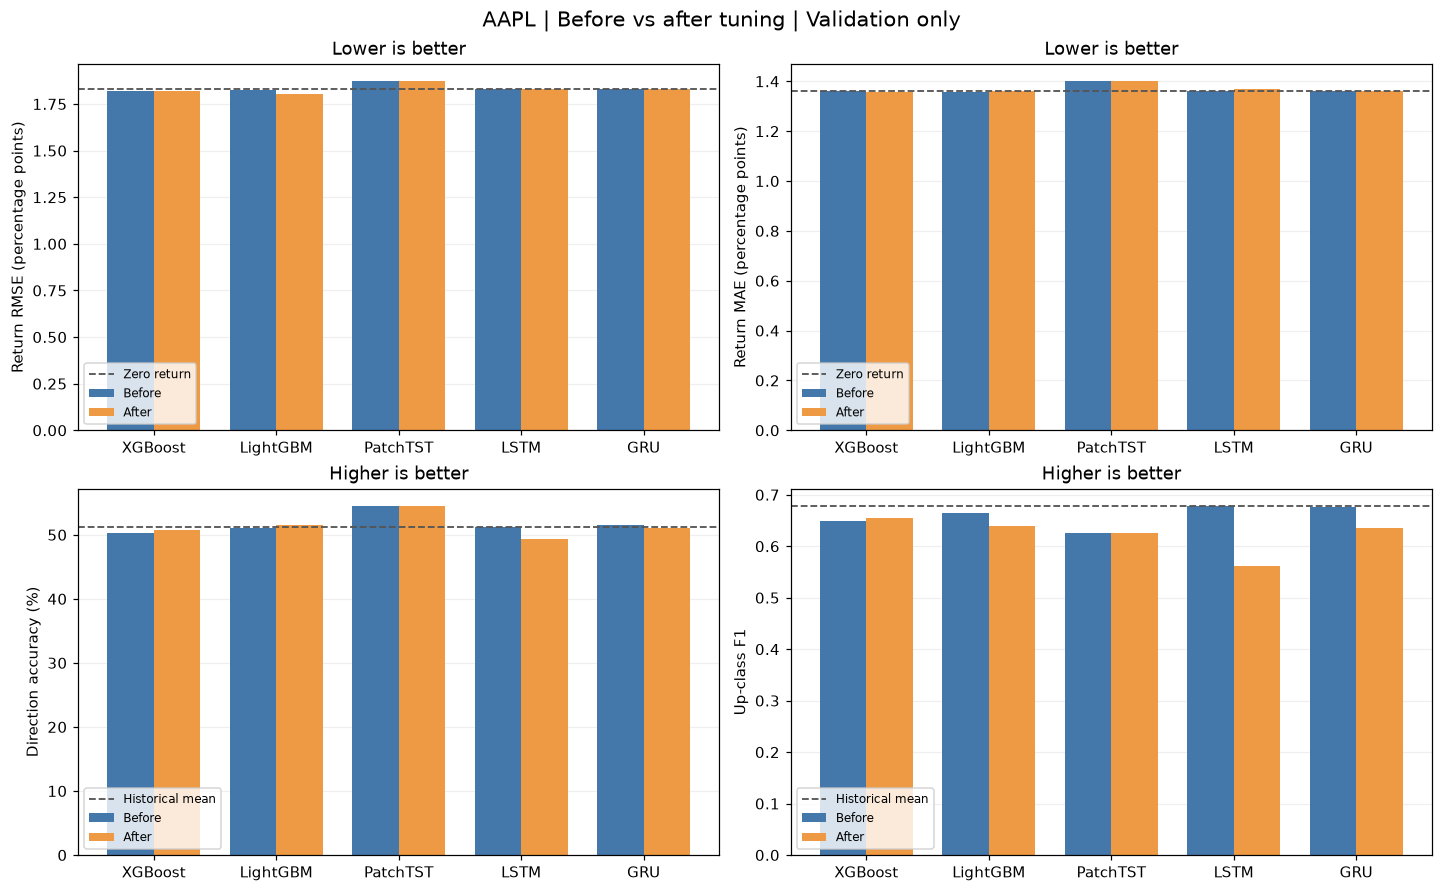

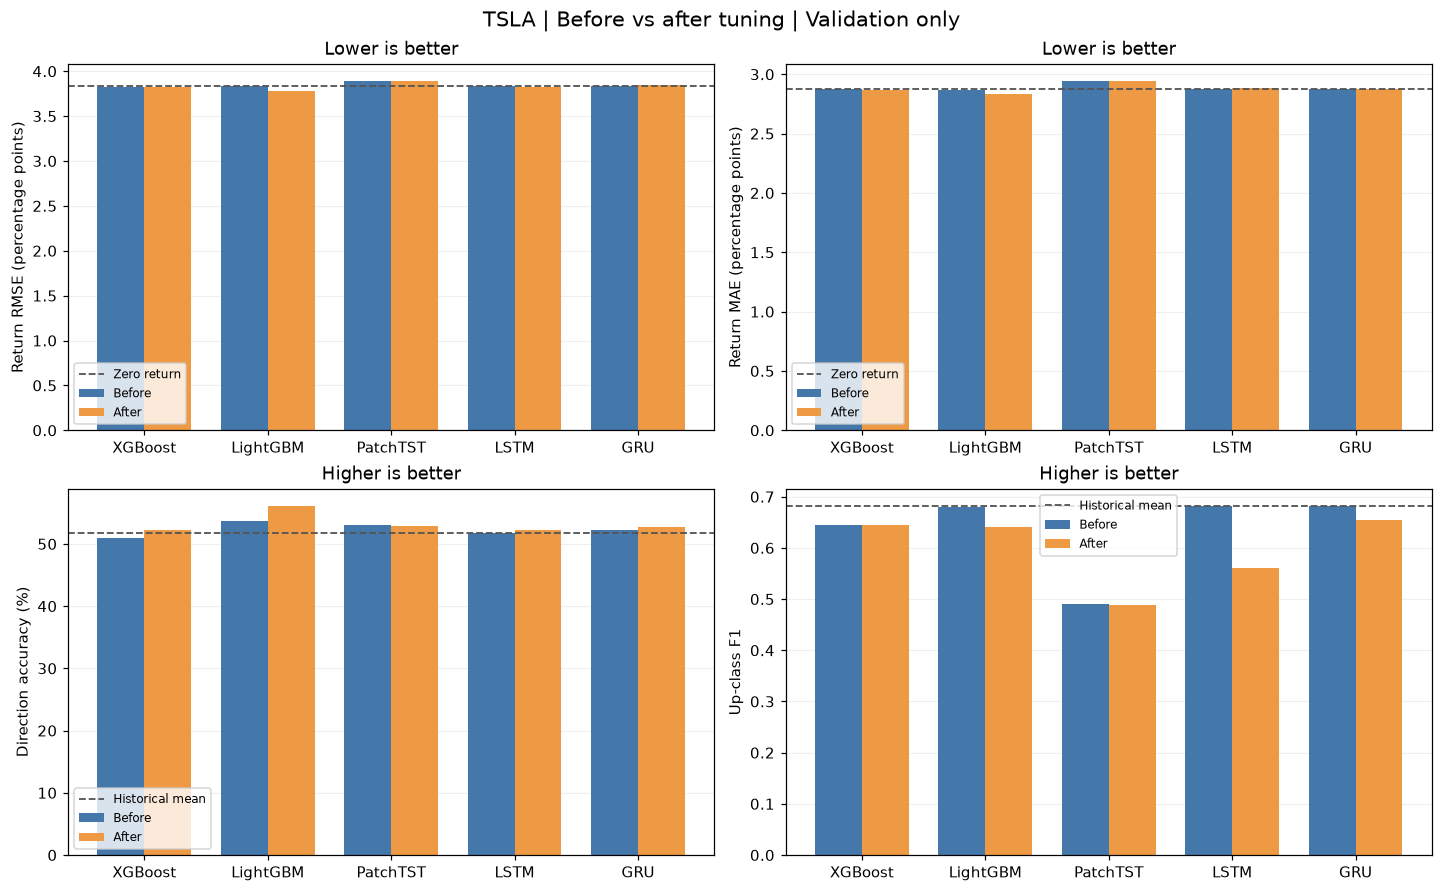

In [5]:
for ticker, before, after in pairs:
    data = comparison[comparison.stock == ticker].set_index('model').loc[MODELS]
    fig, axes = plt.subplots(2, 2, figsize=(13, 8), layout='constrained')
    specs = [('rmse',100,'Return RMSE (percentage points)','Lower is better'),
             ('mae',100,'Return MAE (percentage points)','Lower is better'),
             ('direction_accuracy',100,'Direction accuracy (%)','Higher is better'),
             ('up_f1',1,'Up-class F1','Higher is better')]
    x = np.arange(len(MODELS))
    for ax, (metric, scale, ylabel, hint) in zip(axes.flat, specs):
        ax.bar(x-0.19, data[metric+'_before']*scale, .38, label='Before', color='#4477AA')
        ax.bar(x+0.19, data[metric+'_after']*scale, .38, label='After', color='#EE9944')
        baseline = 'zero_return' if metric in ['rmse','mae'] else 'historical_mean'
        ax.axhline(before['metrics'][baseline][metric]*scale, color='#555555',
                   linestyle='--', linewidth=1.2, label=LABELS[baseline])
        ax.set_xticks(x, [LABELS[m] for m in MODELS])
        ax.set_ylabel(ylabel)
        ax.set_title(hint)
        ax.set_ylim(bottom=0)
        ax.grid(axis='y', alpha=.2)
        ax.set_axisbelow(True)
        ax.legend(fontsize=8)
    fig.suptitle(f'{ticker} | Before vs after tuning | Validation only', fontsize=14)
    plt.show()
    plt.close(fig)

## 5. 哪些模型改善，哪些退步？

所有面板中，向右的正值表示该指标改善，绿色表示改善、红色表示退步。三个面板单位不同，请分别阅读，不把柱长跨面板比较。这里的微小差异是观察值，不代表统计显著性。

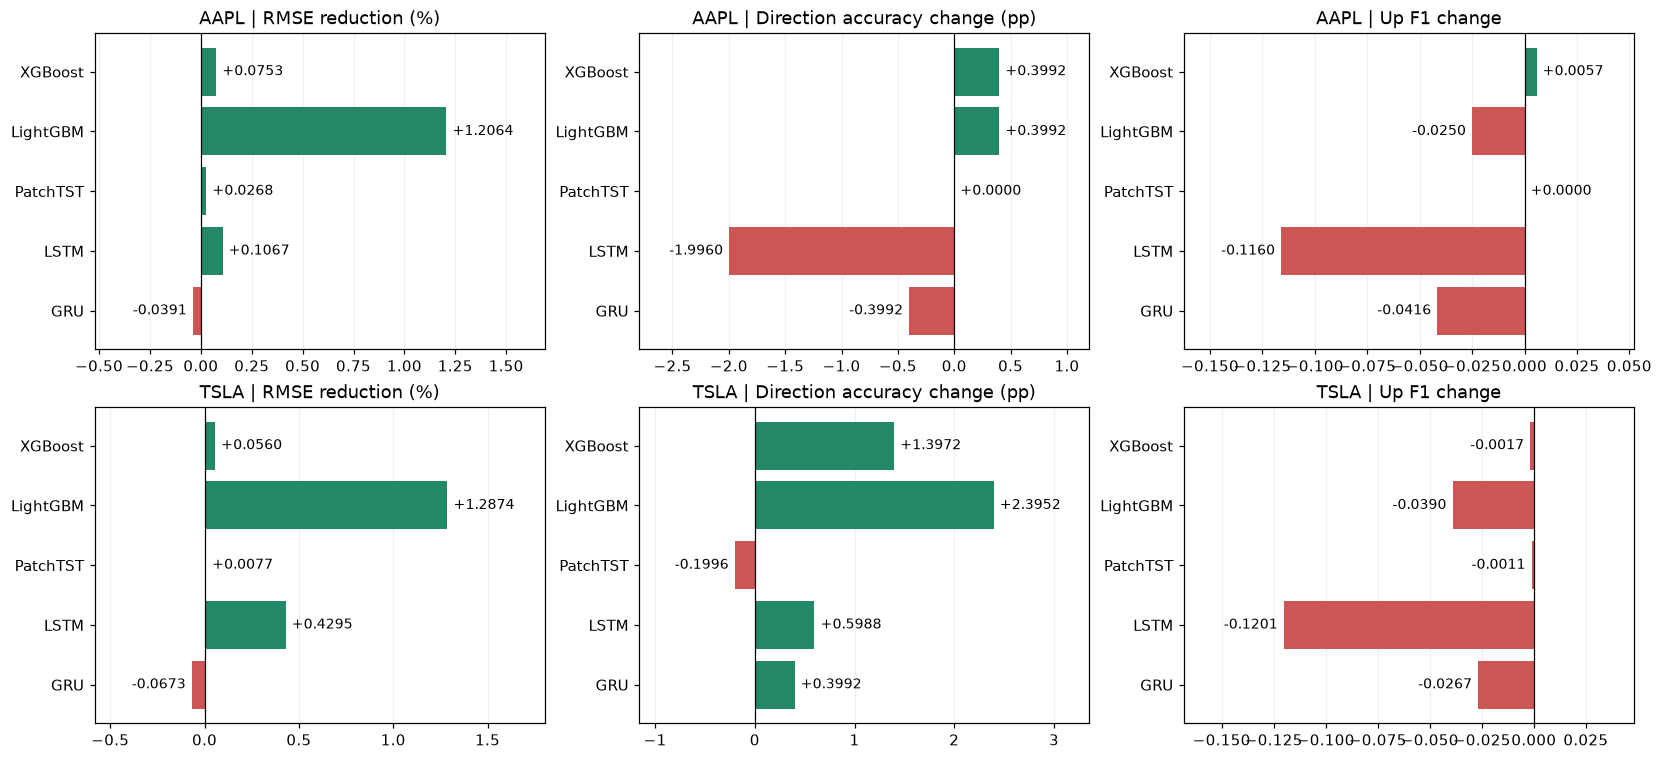

In [6]:
fig, axes = plt.subplots(len(pairs), 3, figsize=(15, 3.4*len(pairs)),
                         squeeze=False, layout='constrained')
specs = [('rmse_improvement_pct','RMSE reduction (%)'),
         ('direction_change_pp','Direction accuracy change (pp)'),
         ('f1_change','Up F1 change')]
for i, (ticker, _, _) in enumerate(pairs):
    data = comparison[comparison.stock == ticker].set_index('model').loc[MODELS]
    for j, (metric, label) in enumerate(specs):
        ax = axes[i,j]
        values = data[metric].to_numpy(dtype=float)
        colors = ['#228866' if v > 1e-12 else '#CC5555' if v < -1e-12 else '#888888' for v in values]
        bars = ax.barh([LABELS[m] for m in MODELS], values, color=colors)
        ax.bar_label(bars, labels=[f'{v:+.4f}' for v in values], padding=4, fontsize=9)
        ax.axvline(0, color='black', linewidth=.8)
        span = max(float(np.nanmax(np.abs(values))), .001)
        ax.set_xlim(min(0,float(np.nanmin(values)))-.4*span,
                    max(0,float(np.nanmax(values)))+.4*span)
        ax.invert_yaxis()
        ax.set_title(f'{ticker} | {label}')
        ax.grid(axis='x', alpha=.2)
        ax.set_axisbelow(True)
plt.show()
plt.close(fig)

## 6. 调优后是否超过简单基线？

对每只股票分别按调优后的 RMSE 排序，并保留三种简单基线。这里的排序只回答“本次验证中谁的回归误差低”，不代表收益策略排名，也不保证方向预测最好。

In [7]:
for ticker, _, after in pairs:
    display(Markdown(f'### {ticker}：调优后的验证结果'))
    ranking = pd.DataFrame(after['metrics']).T.loc[BASELINES + MODELS,
        ['rmse','mae','r2','r2_vs_zero','direction_accuracy','up_f1','predicted_up_rate']]
    ranking = ranking.astype(float).sort_values('rmse').rename(index=LABELS)
    display(ranking.style.format({k:('{:.2%}' if k in ['direction_accuracy','predicted_up_rate']
                                    else '{:.6f}') for k in ranking.columns}))

### AAPL：调优后的验证结果

,rmse,mae,r2,r2_vs_zero,direction_accuracy,up_f1,predicted_up_rate
LightGBM,0.018042,0.013608,0.029092,0.029405,51.50%,0.638930,83.03%
XGBoost,0.018198,0.013574,0.012318,0.012637,50.70%,0.655509,91.82%
LSTM,0.018295,0.013700,0.001717,0.002039,49.30%,0.562069,64.47%
Zero return,0.018314,0.013611,-0.000322,0.000000,48.70%,0.000000,0.00%
GRU,0.018323,0.013615,-0.001289,-0.000966,51.10%,0.634873,82.63%
Historical mean,0.018331,0.013612,-0.002203,-0.001880,51.30%,0.678100,100.00%
PatchTST,0.018712,0.013996,-0.044259,-0.043923,54.49%,0.625000,70.06%
Last return,0.025931,0.019277,-1.005448,-1.004802,50.50%,0.517510,51.30%


### TSLA：调优后的验证结果

,rmse,mae,r2,r2_vs_zero,direction_accuracy,up_f1,predicted_up_rate
LightGBM,0.037813,0.028319,0.025784,0.025785,56.09%,0.640523,70.46%
XGBoost,0.038198,0.028694,0.005848,0.005849,52.30%,0.643815,82.24%
LSTM,0.038232,0.028819,0.004111,0.004112,52.30%,0.561468,57.09%
Zero return,0.038310,0.028789,-0.000001,0.000000,48.30%,0.000000,0.00%
Historical mean,0.038395,0.028800,-0.004418,-0.004416,51.70%,0.681579,100.00%
GRU,0.038433,0.028749,-0.006417,-0.006416,52.69%,0.655022,85.43%
PatchTST,0.038874,0.029403,-0.029640,-0.029639,52.89%,0.489177,40.52%
Last return,0.055047,0.042714,-1.064595,-1.064593,52.50%,0.540541,51.70%


## 7. 根据所选实验自动生成小结

以下文字始终由当前 `RUN_PAIRS` 的完整验证指标生成。RMSE 是主要比较依据，方向和 F1 单独报告，不把一个指标变好写成“整体全面改善”。

In [8]:
for ticker, before, after in pairs:
    data = comparison[comparison.stock == ticker]
    better = data[data.rmse_improvement_pct > 1e-10]
    worse = data[data.rmse_improvement_pct < -1e-10]
    unchanged = len(data)-len(better)-len(worse)
    top = data.loc[data.rmse_after.idxmin()]
    zero = after['metrics']['zero_return']['rmse']
    lines = [f'### {ticker}', '',
             f'- 五个模型中，{len(better)} 个 RMSE 下降、{len(worse)} 个上升、{unchanged} 个基本不变。',
             f'- 调优后五模型中 RMSE 最低的是 **{LABELS[top["model"]]}**：{top["rmse_after"]:.6f}；零收益基线为 {zero:.6f}。']
    for row in data.itertuples():
        change = row.rmse_improvement_pct
        result = f'下降 {change:.4f}%' if change > 1e-10 else f'上升 {-change:.4f}%' if change < -1e-10 else '基本不变'
        lines.append(f'- **{LABELS[row.model]}**：RMSE {result}；方向准确率变化 {row.direction_change_pp:+.3f} 个百分点；上涨 F1 变化 {row.f1_change:+.4f}。')
    if any(item['stock']==ticker for item in provenance_rows):
        lines.append('- 前后代码或环境记录有差异/缺失，因此以上是两个实验版本的结果比较，不能完全归因于超参数。')
    display(Markdown(chr(10).join(lines)))
display(Markdown('**解释边界：这些结果来自单随机种子、同一验证期，且验证集参与过调参和早停。尚未进行统计显著性检验；不能据此宣称最终测试表现改善。**'))

### AAPL

- 五个模型中，4 个 RMSE 下降、1 个上升、0 个基本不变。
- 调优后五模型中 RMSE 最低的是 **LightGBM**：0.018042；零收益基线为 0.018314。
- **XGBoost**：RMSE 下降 0.0753%；方向准确率变化 +0.399 个百分点；上涨 F1 变化 +0.0057。
- **LightGBM**：RMSE 下降 1.2064%；方向准确率变化 +0.399 个百分点；上涨 F1 变化 -0.0250。
- **PatchTST**：RMSE 下降 0.0268%；方向准确率变化 +0.000 个百分点；上涨 F1 变化 +0.0000。
- **LSTM**：RMSE 下降 0.1067%；方向准确率变化 -1.996 个百分点；上涨 F1 变化 -0.1160。
- **GRU**：RMSE 上升 0.0391%；方向准确率变化 -0.399 个百分点；上涨 F1 变化 -0.0416。
- 前后代码或环境记录有差异/缺失，因此以上是两个实验版本的结果比较，不能完全归因于超参数。

### TSLA

- 五个模型中，4 个 RMSE 下降、1 个上升、0 个基本不变。
- 调优后五模型中 RMSE 最低的是 **LightGBM**：0.037813；零收益基线为 0.038310。
- **XGBoost**：RMSE 下降 0.0560%；方向准确率变化 +1.397 个百分点；上涨 F1 变化 -0.0017。
- **LightGBM**：RMSE 下降 1.2874%；方向准确率变化 +2.395 个百分点；上涨 F1 变化 -0.0390。
- **PatchTST**：RMSE 下降 0.0077%；方向准确率变化 -0.200 个百分点；上涨 F1 变化 -0.0011。
- **LSTM**：RMSE 下降 0.4295%；方向准确率变化 +0.599 个百分点；上涨 F1 变化 -0.1201。
- **GRU**：RMSE 上升 0.0673%；方向准确率变化 +0.399 个百分点；上涨 F1 变化 -0.0267。
- 前后代码或环境记录有差异/缺失，因此以上是两个实验版本的结果比较，不能完全归因于超参数。

**解释边界：这些结果来自单随机种子、同一验证期，且验证集参与过调参和早停。尚未进行统计显著性检验；不能据此宣称最终测试表现改善。**